## Practical 03: Iris Flower Classification

### Aim
Classify Setosa, Versicolor and Virginica from sepal and petal measurements.

### Model
K-Nearest Neighbors (KNN)

### Data
scikit-learn Iris benchmark: 150 flowers, four measurements in centimetres and three species.

### Theory
KNN predicts the majority class of the five closest training observations. Standardization prevents a feature with a larger numerical scale from dominating Euclidean distance.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The test split contains only 38 flowers. Results depend on the split and do not measure performance on every flower species.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


In [1]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Classes: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}
Train: 112 | Test: 38 | Features: 4
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        12
           1      0.812     1.000     0.897        13
           2      1.000     0.769     0.870        13

    accuracy                          0.921        38
   macro avg      0.938     0.923     0.922        38
weighted avg      0.936     0.921     0.920        38

accuracy: 0.9211
macro_f1: 0.9220
baseline_accuracy: 0.3158
First five held-out predictions: [0 1 1 1 0]


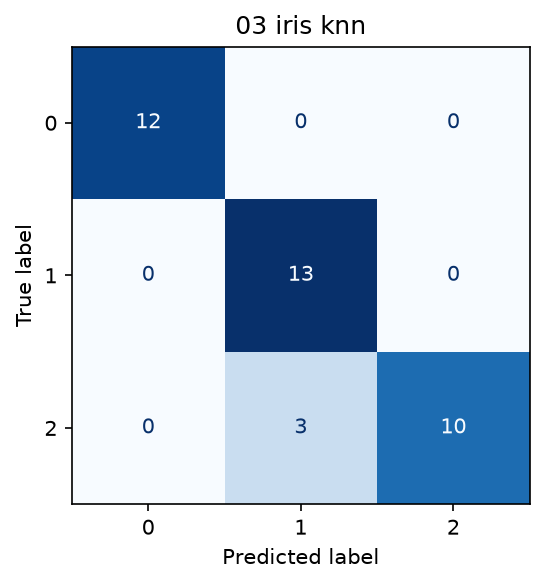

In [3]:
dataset = load_iris(as_frame=True)
X, y = dataset.data, dataset.target
print('Classes:', dict(enumerate(dataset.target_names)))
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
metrics = evaluate(model, X, y, '03_iris_knn')

### Result and conclusion
Measured results: accuracy = 0.9211; macro_f1 = 0.9220; baseline_accuracy = 0.3158. The test split contains only 38 flowers. Results depend on the split and do not measure performance on every flower species.